In [18]:
from __future__ import print_function, division

import os, sys
import numpy as np
import pandas as pd

from Bio import SeqIO

# log library versions and working dir
from scipy.version import full_version as spversion
from Bio import __version__ as bioversion

print("Python:    ", sys.version)
print("Numpy:     ", np.__version__)
print("Scipy:     ", spversion)
print("Biopython: ", bioversion)
print("Workdir:   ", os.getcwd())

Python:     3.9.13 (main, Aug 25 2022, 23:51:50) [MSC v.1916 64 bit (AMD64)]
Numpy:      1.23.5
Scipy:      1.9.2
Biopython:  1.79
Workdir:    C:\Projects\MHC_predictor\experiments\prediction_pipeline


In [20]:
# reading with BioPython
ORGANISMS = ["human", "mouse"]

PATH_TO_WRITE_FILES = "G:/My Drive/Work/ITMO/data/decoy"

per_organism_file = {"human":"G:/My Drive/Work/ITMO/data/gencode file/gencode.v43.pc_translations.fa",
                     "mouse":"G:/My Drive/Work/ITMO/data/gencode file/gencode.vM32.pc_translations.fa"}


per_organism_proteins = dict()
for organism_to_use in ORGANISMS:
    per_organism_proteins[organism_to_use] = [ protein for protein in SeqIO.parse(per_organism_file[organism_to_use],"fasta")]




print(len(per_organism_proteins[ORGANISMS[0]]))

111276


In [21]:
# check if all fasta ID lines have the same number of 'fields'
for organism_to_use in ORGANISMS:
    proteins =   per_organism_proteins[organism_to_use]
    numSegmentsInName = pd.Series([len(protein.id.split('|')) for protein in proteins])
    print(numSegmentsInName.value_counts().to_string())


8    111276
8    66800


In [22]:
# create a dataframe
gencodeFastaIdFields = [
    'unknown_id',
    'transcript_id',
    'gene_id',
    'Havana_gene_id',
    'Havana_transcript_id',
    'transcript_name',
    'gene_name',
    'length'
]
per_organism_proteome_df = dict()

for organism_to_use in ORGANISMS:
    proteins =   per_organism_proteins[organism_to_use]
    dfProteome = pd.DataFrame(
    [protein.id.split('|')[5:8] + [str(protein.seq)] for protein in proteins],
    columns = gencodeFastaIdFields[5:8] + ['sequence'],)
    dfProteome.length = pd.to_numeric(dfProteome.length)
    
    per_organism_proteome_df[organism_to_use] = dfProteome
# we throw away the lengthy first 5 fields; transcript_name is anyway unique
    # verification of length field
    print(sum(dfProteome.length != dfProteome.sequence.str.len()))

# convert length field to ingere


0
0


In [23]:
per_organism_proteome_df[organism_to_use].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66800 entries, 0 to 66799
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   transcript_name  66800 non-null  object
 1   gene_name        66800 non-null  object
 2   length           66800 non-null  int64 
 3   sequence         66800 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.0+ MB


In [24]:
per_organism_proteome_df[organism_to_use].nunique()

transcript_name    66800
gene_name          22190
length              2591
sequence           57411
dtype: int64

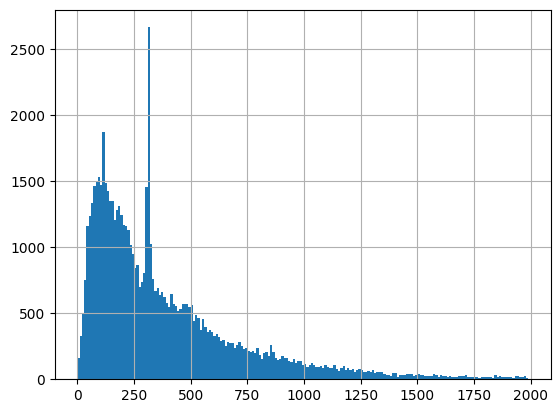

In [25]:
# distribution of lengths
dfProteome.length.hist(bins = [x for x in range(0,2000,10)]);

In [26]:
# print some peptides:
for index,row in per_organism_proteome_df[organism_to_use][0:10].iterrows():
    print(row['transcript_name'])
    print(row['sequence'])

Xkr4-201
MAAKSDGRLKMKKSSDVAFTPLQNSDNSGSVQGLAPGLPSGSGAEDTEAAGGGCCPDGGGCSRCCCCCAGSGGSAGSGGSGGGGRGSGAGSAALCLRLGREQRRYSLWDCLWILAAVAVYFADVGTDIWLAVDYYLRGQRWWFGLTLFFVVLGSLSVQVFSFRWFVHDFSTEDSSTTTTSSCQQPGADCKTVVSSGSAAGEGEVRPSTPQRQASNASKSNIAATNSGSNSNGATRTSGKHRSASCSFCIWLLQSLIHILQLGQIWRYLHTIYLGIRSRQSGESGRWRFYWKMVYEYADVSMLHLLATFLESAPQLVLQLCIIVQTHSLQALQGFTAAASLVSLAWALASYQKALRDSRDDKKPISYMAVIIQFCWHFFTIAARVITFALFASVFQLYFGIFIVLHWCIMTFWIVHCETEFCITKWEEIVFDMVVGIIYIFSWFNVKEGRTRCRLFIYYFVILLENTALSALWYLYKAPQIADAFAIPALCVVFSSFLTGVVFMLMYYAFFHPNGPRFGQSPSCACDDPATAFSLPPEVATSTLRSISNNRSVASDRDQKFAERDGCVPVFQVRPTAPPTPSSRPPRIEESVIKIDLFRNRYPAWERHVLDRSLRKAILAFECSPSPPRLQYKDDALIQERLEYETTL
Rp1-202
MLEKLQVSPKMSDTPSTSFSMIHLTSEGQVPSPRHSNITHPVVAKRISFYKSGDPQFGGVRVVVNPRSFKTFDALLDSLSRKVPLPFGVRNISTPRGRHSITRLEELEDGKSYVCSHNKKVLPVDLDKARRRPRPWLSSRSISTHVQLCPATANMSTMAPGMLRAPRRLVVFRNGDPKNKHVVLLSRRITQSFEAFLQYLTQVMQCPVAKLYATDGRKVPSLQAVILSSGAVVAAGREPFKPGNYDIQKYLLPAKLPGISHRVHQKGKAKIEKRKSGNWKVSINTSDFPNAGTSSQIYIVLYGHCRSSAPIYLYGRDGTRFQDGHEDNFTIMVGD

In [27]:
# fragment the proteome
def shredProteins(listOfProteins, minLength, maxLength):
    """Cut all proteins in the list in fragments of length uniformly distributed in the given range"""
    
    assert (minLength <= maxLength), "Invalid length range"
    
    fragments = []
    for protein in listOfProteins:
        while(True):
            if (len(protein) < minLength):
                # do not gather short rubbish
                break
            fragmentLength = np.random.randint(minLength, maxLength + 1)
            fragments.append(protein[0:fragmentLength])
            protein = protein[fragmentLength:]
    return fragments

Class I
Number of peptides: 4372536
Length range: 8-12
Class II
Number of peptides: 2430705
Length range: 12-24
Class I
Number of peptides: 2832111
Length range: 8-12
Class II
Number of peptides: 1574435
Length range: 12-24


array([[<AxesSubplot: title={'center': '0'}>]], dtype=object)

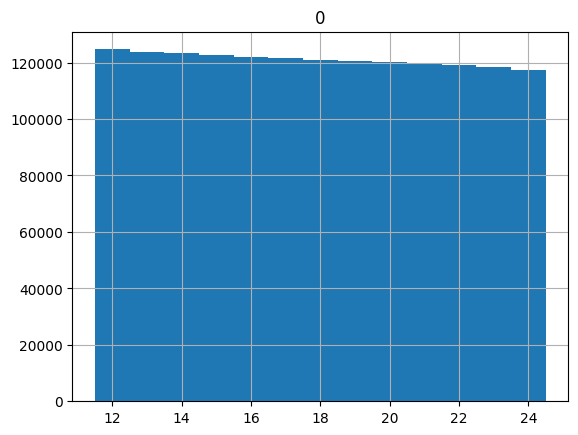

In [30]:
per_organism_per_class_fragmets = dict()

for organism_to_use in ORGANISMS:
    dfProteome = per_organism_proteome_df[organism_to_use]
    per_organism_per_class_fragmets[organism_to_use] = dict()

    fragmentsClassI = shredProteins(dfProteome.sequence, 8, 12)
    fragmentsClassII = shredProteins(dfProteome.sequence, 12, 24)
    
    print("Class I")
    lengths = [len(f) for f in fragmentsClassI]
    print("Number of peptides:", len(fragmentsClassI))
    print("Length range: {}-{}".format(min(lengths), max(lengths)))
    print("Class II")
    lengths = [len(f) for f in fragmentsClassII]
    print("Number of peptides:", len(fragmentsClassII))
    print("Length range: {}-{}".format(min(lengths), max(lengths)))
    
    with open(f'{PATH_TO_WRITE_FILES}/decoy-{organism_to_use}-class-i.txt', 'w') as f:
        for fragment in fragmentsClassI:
            f.write(fragment + '\n')

    with open(f'{PATH_TO_WRITE_FILES}/decoy-{organism_to_use}-class-ii.txt', 'w') as f:
        for fragment in fragmentsClassII:
            f.write(fragment + '\n')

pd.DataFrame(lengths).hist(bins=[x+0.5 for x in range(min(lengths) - 1, max(lengths) + 1)])
